# Femicide over time

Monthly recorded cases across the dataset. Cases known only by year are filed under **December 31**, which creates
false year-end spikes, so they are excluded from the monthly views.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from femicide import load_cases, load_population, top_categories, save

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 11})
ACCENT = "#8E2C48"

In [2]:
cases = load_cases()
dated = cases[~cases["DATE_IS_PLACEHOLDER"]]
print(f"{len(cases):,} cases; {cases['DATE_IS_PLACEHOLDER'].sum():,} have a year-only placeholder date")
print(f"Date range: {cases['DATE'].min():%b %Y} to {cases['DATE'].max():%b %Y}")

7,976 cases; 560 have a year-only placeholder date
Date range: Jan 2015 to Jul 2024


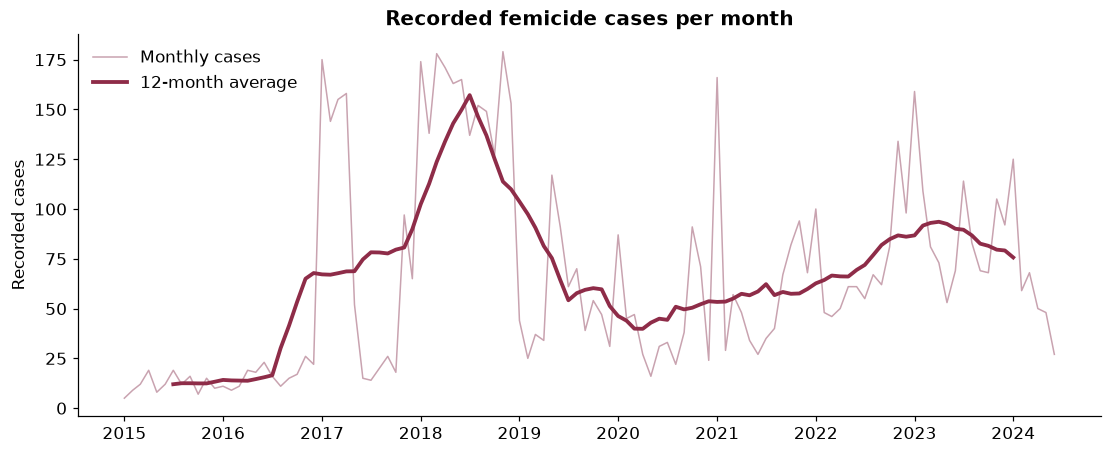

In [3]:
monthly = dated.set_index("DATE").resample("MS").size()
monthly = monthly[:-1]  # the last month is only partly collected

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly.index, monthly.values, color="#c9a3b0", lw=1, label="Monthly cases")
ax.plot(monthly.index, monthly.rolling(12, center=True).mean(), color=ACCENT, lw=2.5, label="12-month average")
ax.set(ylabel="Recorded cases", title="Recorded femicide cases per month")
ax.legend(frameon=False)
save(fig, "monthly_cases.png")

## Is there a seasonal pattern?

Coverage differs a lot between years, so each month is measured as its **share of that year's cases**, then
averaged over full years. A flat pattern would put every month near 8.3%.

DATE
Jan    12.1
Feb     7.3
Mar     8.3
Apr     8.7
May     7.4
Jun     7.5
Jul     7.5
Aug     6.6
Sep     7.2
Oct     8.2
Nov    11.3
Dec     7.9
dtype: float64

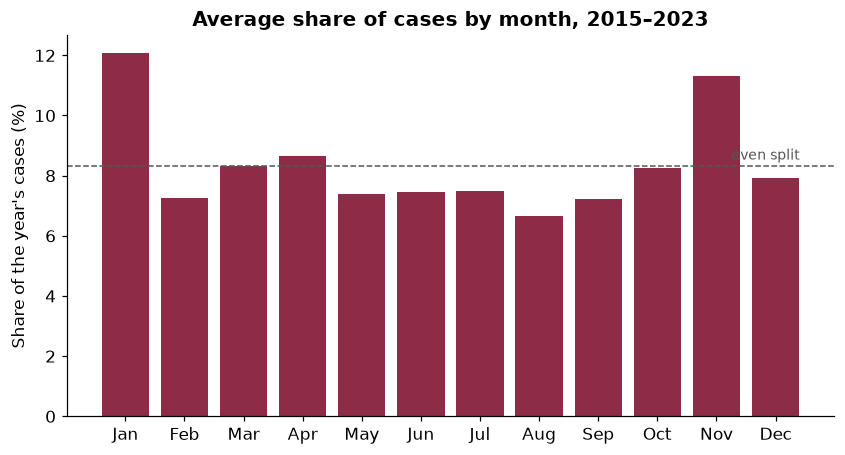

In [4]:
full_years = dated[dated["DATE"].dt.year.between(2015, 2023)]
share = (full_years.groupby([full_years["DATE"].dt.year, full_years["DATE"].dt.month]).size()
         .groupby(level=0).transform(lambda s: s / s.sum()).unstack())
avg_share = share.mean() * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
months = pd.to_datetime(avg_share.index, format="%m").strftime("%b")
ax.bar(months, avg_share.values, color=ACCENT)
ax.axhline(100 / 12, color="#555", ls="--", lw=1)
ax.text(11.4, 100 / 12 + 0.2, "even split", ha="right", fontsize=9, color="#555")
ax.set(ylabel="Share of the year's cases (%)", title="Average share of cases by month, 2015–2023")
save(fig, "seasonality.png")
avg_share.round(1).set_axis(months)

## Notes

- Changes in yearly totals mostly reflect how many cases the database collected, not real changes in incidence,
  so the monthly view is the more reliable one.
- Some cases are dated by when the body was found or when the victim was last seen, not the date of death.